#  Day 01 Master Lab Walkthrough — NLP & Computational Linguistics
**Course:** NLP & Computer Vision (PGCP-AI) — CDAC  
**Student:** abs6187 (`23f2000876@ds.study.iitm.ac.in`)  

---

## [Objective] Overview of Day 1 Content
This master notebook integrates all **9 lab exercises** taught by Ma'am in Sessions 1 and 2:

| Lab # | Topic | Key Concepts | Libraries |
|---|---|---|---|
| **Lab 1** | Formal vs Natural Language Parsing | Ambiguity in natural language vs deterministic AST | `ast` (stdlib) |
| **Lab 2** | Dependency Parsing with spaCy | Syntactic structure and heads | `spacy` (`en_core_web_sm`) |
| **Lab 3** | Zipf's Law Distribution | Word rank vs frequency log-log plot | `nltk.corpus.gutenberg`, `matplotlib` |
| **Lab 4** | Syntagmatic & Paradigmatic Relations | PMI Bigram Collocations & WordNet Synsets | `nltk.collocations`, `nltk.corpus.wordnet` |
| **Lab 5** | Multi-Level NLP Pipeline | Morphology, POS, Dependency & NER | `spacy` |
| **Lab 6** | Mini Dialogue System | NLU (Intent + Slot) and NLG response generation | `re` (stdlib) |
| **Lab 7** | Sentiment Analysis | Polarity scoring & emoji classification | `textblob` |

In [1]:
# [Google Colab & Drive Setup - cdac74abhlak@gmail.com]
# Run this cell if executing on Google Colab to mount Google Drive
import os
try:
    import google.colab
    IN_COLAB = True
    from google.colab import drive
    drive.mount('/content/drive')
    drive_dir = '/content/drive/MyDrive/NLP_CDAC/notes/day-01'
    os.makedirs(drive_dir, exist_ok=True)
    os.chdir(drive_dir)
    print('[OK] Google Drive linked for cdac74abhlak@gmail.com')
    print('[DIR] Working Directory:', os.getcwd())
    # Uncomment below to install required packages on Colab runtime:
    # !pip install -q spacy nltk matplotlib textblob
except ImportError:
    IN_COLAB = False
    print('[OK] Running locally in VS Code / Antigravity IDE (Account: cdac74abhlak@gmail.com)')


[OK] Running locally in VS Code / Antigravity IDE (Account: cdac74abhlak@gmail.com)


--- 
##  Lab 1: Formal Language vs. Natural Language (`parser_demo.py`)

**Concept:** Formal languages (like Python or math expressions) have **zero ambiguity** — every expression has exactly one deterministic parse tree. Natural language (human speech), however, is full of **structural and syntactic ambiguity**.

In [2]:
import ast

# 1. An artificial language (Python code): has exactly ONE fixed parse tree
expression = "x = a + b * c"
tree = ast.parse(expression)
print("1. ARTIFICIAL / FORMAL LANGUAGE PARSE TREE:")
print(f"Expression: {expression}")
print(ast.dump(tree, indent=2))

# 2. A natural-language sentence: just an ambiguous sequence of characters
sent = "I saw the man with the telescope"
print("\n2. NATURAL LANGUAGE STRING:")
print(f"Sentence: '{sent}'")
print("Tokens:  ", sent.split())
print("\n[WARNING] Ambiguity Note: Did I use the telescope to see the man? Or did the man have the telescope?")

1. ARTIFICIAL / FORMAL LANGUAGE PARSE TREE:
Expression: x = a + b * c
Module(
  body=[
    Assign(
      targets=[
        Name(id='x', ctx=Store())],
      value=BinOp(
        left=Name(id='a', ctx=Load()),
        op=Add(),
        right=BinOp(
          left=Name(id='b', ctx=Load()),
          op=Mult(),
          right=Name(id='c', ctx=Load()))))])

2. NATURAL LANGUAGE STRING:
Sentence: 'I saw the man with the telescope'
Tokens:   ['I', 'saw', 'the', 'man', 'with', 'the', 'telescope']

[WARNING] Ambiguity Note: Did I use the telescope to see the man? Or did the man have the telescope?


---
##  Lab 2: spaCy Dependency Parsing (`spaCy_Dependency _Parse.py`)

**Concept:** spaCy builds a dependency tree showing grammatical relations (subject, object, modifier) between tokens and their head words.

In [3]:
import spacy
nlp = spacy.load("en_core_web_sm")

# 4 classic ambiguous sentences from Session 1 slides
sentences = [
    "Visiting aunts can be a nuisance.",
    "She went to the bank.",
    "I saw the man with the telescope.",
    "Can you pass the salt?"
]

for s in sentences:
    print(f"Sentence: {s}")
    print(f"{'TOKEN':<12} {'DEP LABEL':<12} {'HEAD WORD':<12}")
    print("-" * 38)
    for tok in nlp(s):
        print(f"{tok.text:<12} {tok.dep_:<12} {tok.head.text:<12}")
    print()

Sentence: Visiting aunts can be a nuisance.
TOKEN        DEP LABEL    HEAD WORD   
--------------------------------------
Visiting     amod         aunts       
aunts        nsubj        be          
can          aux          be          
be           ROOT         be          
a            det          nuisance    
nuisance     attr         be          
.            punct        be          

Sentence: She went to the bank.
TOKEN        DEP LABEL    HEAD WORD   
--------------------------------------
She          nsubj        went        
went         ROOT         went        
to           prep         went        
the          det          bank        
bank         pobj         to          
.            punct        went        

Sentence: I saw the man with the telescope.
TOKEN        DEP LABEL    HEAD WORD   
--------------------------------------
I            nsubj        saw         
saw          ROOT         saw         
the          det          man         
man          dobj   

---
##  Lab 3: Zipf's Law with NLTK (`zipf_law.py`)

**Concept:** Zipf's Law states that in any natural language corpus, the frequency of any word is **inversely proportional to its rank in the frequency table**:

$$\text{Frequency} \approx \frac{k}{\text{Rank}}$$

On a log-log plot (log(Rank) vs log(Frequency)), Zipf's Law appears as a downward straight line with slope $\approx -1$.

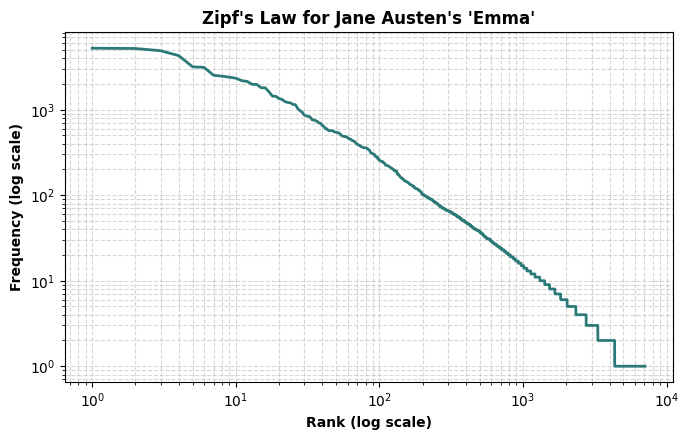

Top 10 Most Frequent Words:
  Rank 1  : 'to      ' with frequency 5,239
  Rank 2  : 'the     ' with frequency 5,201
  Rank 3  : 'and     ' with frequency 4,896
  Rank 4  : 'of      ' with frequency 4,291
  Rank 5  : 'i       ' with frequency 3,178
  Rank 6  : 'a       ' with frequency 3,129
  Rank 7  : 'it      ' with frequency 2,528
  Rank 8  : 'her     ' with frequency 2,469
  Rank 9  : 'was     ' with frequency 2,398
  Rank 10 : 'she     ' with frequency 2,340


In [4]:
import collections
import matplotlib.pyplot as plt
import nltk
nltk.download('gutenberg', quiet=True)

# Load Jane Austen's Emma from Gutenberg corpus
words = [w.lower() for w in nltk.corpus.gutenberg.words("austen-emma.txt") if w.isalpha()]
freq = collections.Counter(words).most_common()

ranks = range(1, len(freq) + 1)
frequencies = [count for _, count in freq]

# Log-Log plot
plt.figure(figsize=(7, 4.5))
plt.loglog(ranks, frequencies, color='#2B7A78', linewidth=2)
plt.xlabel("Rank (log scale)", fontweight='bold')
plt.ylabel("Frequency (log scale)", fontweight='bold')
plt.title("Zipf's Law for Jane Austen's 'Emma'", fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Top 10 Most Frequent Words:")
for r, (word, cnt) in enumerate(freq[:10], start=1):
    print(f"  Rank {r:<2} : '{word:<8}' with frequency {cnt:,}")

---
##  Lab 4: Syntagmatic & Paradigmatic Relations (`paradigmatic_syntagmatic.py` & `collocations_wordnet.py`)

- **Syntagmatic Relation:** *"Words that keep company"* (horizontal). Words that frequently appear together (Collocations, e.g., *"barouche landau"*, *"brunswick square"*). Measured via **PMI (Pointwise Mutual Information)**.
- **Paradigmatic Relation:** *"Words that can substitute for each other"* (vertical). Words with shared semantic categories, synonyms, and hypernyms (e.g. WordNet synsets for *"car"*).

In [5]:
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures
from nltk.corpus import gutenberg, wordnet as wn
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# 1. Syntagmatic: Top 10 PMI Bigrams in Emma
emma_words = [w.lower() for w in gutenberg.words("austen-emma.txt") if w.isalpha()]
finder = BigramCollocationFinder.from_words(emma_words)
finder.apply_freq_filter(5)  # Filter out rare bigrams

print("=" * 50)
print("1. TOP 10 PMI COLLOCATIONS (Syntagmatic)")
print("=" * 50)
for i, bg in enumerate(finder.nbest(BigramAssocMeasures.pmi, 10), start=1):
    print(f"  {i:>2}. {' '.join(bg)}")

# 2. Paradigmatic: WordNet Senses of 'car'
print("\n" + "=" * 50)
print("2. WORDNET SENSES OF 'CAR' (Paradigmatic)")
print("=" * 50)
for syn in wn.synsets("car")[:3]:
    print(f"\nSynset:    {syn.name()}")
    print(f"Synonyms:  {', '.join(syn.lemma_names())}")
    hypernyms = [h.name() for h in syn.hypernyms()]
    print(f"Hypernyms: {', '.join(hypernyms)}")

1. TOP 10 PMI COLLOCATIONS (Syntagmatic)
   1. barouche landau
   2. o clock
   3. court plaister
   4. brunswick square
   5. sore throat
   6. d ye
   7. don t
   8. mill farm
   9. william larkins
  10. baked apples

2. WORDNET SENSES OF 'CAR' (Paradigmatic)



Synset:    car.n.01
Synonyms:  car, auto, automobile, machine, motorcar
Hypernyms: motor_vehicle.n.01

Synset:    car.n.02
Synonyms:  car, railcar, railway_car, railroad_car
Hypernyms: wheeled_vehicle.n.01

Synset:    car.n.03
Synonyms:  car, gondola
Hypernyms: compartment.n.02


---
## [CHART] Lab 5: Sentence Through the Levels of NLP (`spacy_One_Row_Per_Token.py`)

**Concept:** Illustrates how a single sentence is analyzed across all linguistic levels in modern NLP:
- **Morphology:** Lemmas, morphological features (tense, number, person)
- **Syntax:** POS tags, Dependency heads & labels
- **Semantics:** Named Entities (NER)

In [6]:
doc = nlp("The children in Pune didn't eat the mangoes because they were raw.")

print(f"{'TOKEN':<12} {'LEMMA':<12} {'MORPHOLOGY':<26} {'POS':<8} {'DEP':<10} {'HEAD'}")
print("-" * 80)

for t in doc:
    print(
        f"{t.text:<12} "
        f"{t.lemma_:<12} "
        f"{str(t.morph):<26} "
        f"{t.pos_:<8} "
        f"{t.dep_:<10} "
        f"{t.head.text}"
    )

print("\nNamed Entities Discovered:")
for ent in doc.ents:
    print(f"  • '{ent.text}' -> Label: {ent.label_} ({spacy.explain(ent.label_)})")

TOKEN        LEMMA        MORPHOLOGY                 POS      DEP        HEAD
--------------------------------------------------------------------------------
The          the          Definite=Def|PronType=Art  DET      det        children
children     child        Number=Plur                NOUN     nsubj      eat
in           in                                      ADP      prep       children
Pune         Pune         Number=Sing                PROPN    pobj       in
did          do           Tense=Past|VerbForm=Fin    AUX      aux        eat
n't          not          Polarity=Neg               PART     neg        eat
eat          eat          VerbForm=Inf               VERB     ROOT       eat
the          the          Definite=Def|PronType=Art  DET      det        mangoes
mangoes      mango        Number=Plur                NOUN     dobj       eat
because      because                                 SCONJ    mark       were
they         they         Case=Nom|Number=Plur|Person=3|P

---
## Bot Lab 6: Mini Dialogue System (`mini_dialogue_system.py`)

**Concept:** Simple NLU (Intent detection + Slot filling) coupled with template-based NLG for a task-oriented flight booking chatbot.

In [7]:
import re

def understand(text):
    # NLU: Natural Language Understanding
    text = text.lower()
    intent = "book_flight" if re.search(r"\b(book|fly|flight)\b", text) else "unknown"
    slots = re.findall(r"\b(from|to)\s+(\w+)", text)
    return intent, slots

def generate(intent, slots):
    # NLG: Natural Language Generation
    if intent == "book_flight":
        if slots:
            return f"Searching flights for {slots[0][1].title()} ..."
        return "Sure. Where are you flying from, and to?"
    return "Sorry, I can only help with flights."

# Automated dialogue test run
test_prompts = [
    "I want to book a flight",
    "Can I fly to Mumbai?",
    "What is your name?"
]

print("DIALOGUE SYSTEM DEMO:")
print("-" * 40)
for p in test_prompts:
    intent, slots = understand(p)
    reply = generate(intent, slots)
    print(f"You : {p}")
    print(f"Bot : {reply}\n")

DIALOGUE SYSTEM DEMO:
----------------------------------------
You : I want to book a flight
Bot : Searching flights for Book ...

You : Can I fly to Mumbai?
Bot : Searching flights for Mumbai ...

You : What is your name?
Bot : Sorry, I can only help with flights.



---
##  Lab 7: Sentiment Analysis (`Sentiment_Analysis.py`)

**Concept:** TextBlob computes a **Polarity Score** between `-1.0` (extremely negative) and `+1.0` (extremely positive), with `0.0` being neutral.

In [8]:
from textblob import TextBlob

sample_reviews = [
    "The food was absolutely delicious and the service was superb!",
    "The movie was okay, nothing special.",
    "Terrible experience. The flight was delayed for 5 hours and staff was rude."
]

print("=" * 60)
print("SENTIMENT ANALYSIS WITH TEXTBLOB")
print("=" * 60)

for review in sample_reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    
    if polarity > 0.1:
        sentiment = "Positive [Positive]"
    elif polarity < -0.1:
        sentiment = "Negative [Negative]"
    else:
        sentiment = "Neutral [Neutral]"
        
    print(f"Review   : '{review}'")
    print(f"Polarity : {polarity:.2f}")
    print(f"Verdict  : {sentiment}\n")

SENTIMENT ANALYSIS WITH TEXTBLOB
Review   : 'The food was absolutely delicious and the service was superb!'
Polarity : 1.00
Verdict  : Positive [Positive]

Review   : 'The movie was okay, nothing special.'
Polarity : 0.43
Verdict  : Positive [Positive]

Review   : 'Terrible experience. The flight was delayed for 5 hours and staff was rude.'
Polarity : -0.65
Verdict  : Negative [Negative]

